# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [3]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('Clean_Aviation_Data.csv', low_memory=False)
print("=" * 50)
print("CLEAN DATA")
print(f"Total operational records available: {df.shape[0]} rows, {df.shape[1]} columns")

CLEAN DATA
Total operational records available: 17879 rows, 34 columns


## Exploratory Data Analysis  
- Load in the cleaned data

In [5]:
df = pd.read_csv('Clean_Aviation_Data.csv', low_memory=False)
print("=" * 50)
print("EDA: DATASET INITIALIZATION")
print(f"Total Cleaned Records:{df.shape[0]} rows")
print(f"Total Retained Features: {df.shape[1]} columns")
print("\nFirst 3 Recors Preview:")
print(df[['make', 'model', 'total.aboard', 'injury.rate', 'hull.destroyed']].head(5))
print("=" * 50)

EDA: DATASET INITIALIZATION
Total Cleaned Records:17879 rows
Total Retained Features: 34 columns

First 3 Recors Preview:
           make      model  total.aboard  injury.rate  hull.destroyed
0        BOEING        747           588          0.0               0
1         PIPER  PA-28-140             2          1.0               1
2  DE HAVILLAND      DHC-6             5          0.2               0
3        BOEING    727-200           100          0.0               0
4         BEECH        C35             1          0.0               0


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [6]:
fleet_grouped = df.groupby('make_model_id').agg(
    total_accidents=('event.id', 'count'),
    avg_aboard=('total.aboard', 'mean'),
    hull_destruction_rate=('hull.destroyed', 'mean'),
    mean_injury_rate=('injury.rate', 'mean')
).reset_index()

robust_models = fleet_grouped[fleet_grouped['total_accidents'] >= 50]

small_aircraft = robust_models[robust_models['avg_aboard'] <= 20]
large_aircraft = robust_models[robust_models['avg_aboard'] > 20]

print("=" * 60)
print(f"FLEET SEGMENTATION SUMMARY (PASSENGER THRESHOLD = 20)")
print(f"Total Robust Models Found (N >= 50): {len(robust_models)}")
print(f"Smaller Airplanes Fleet Group: {len(small_aircraft)} models")
print(f"Larger Passenger Airplanes Fleet Group: {len(large_aircraft)} models")
print("=" * 60)

FLEET SEGMENTATION SUMMARY (PASSENGER THRESHOLD = 20)
Total Robust Models Found (N >= 50): 63
Smaller Airplanes Fleet Group: 58 models
Larger Passenger Airplanes Fleet Group: 5 models


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

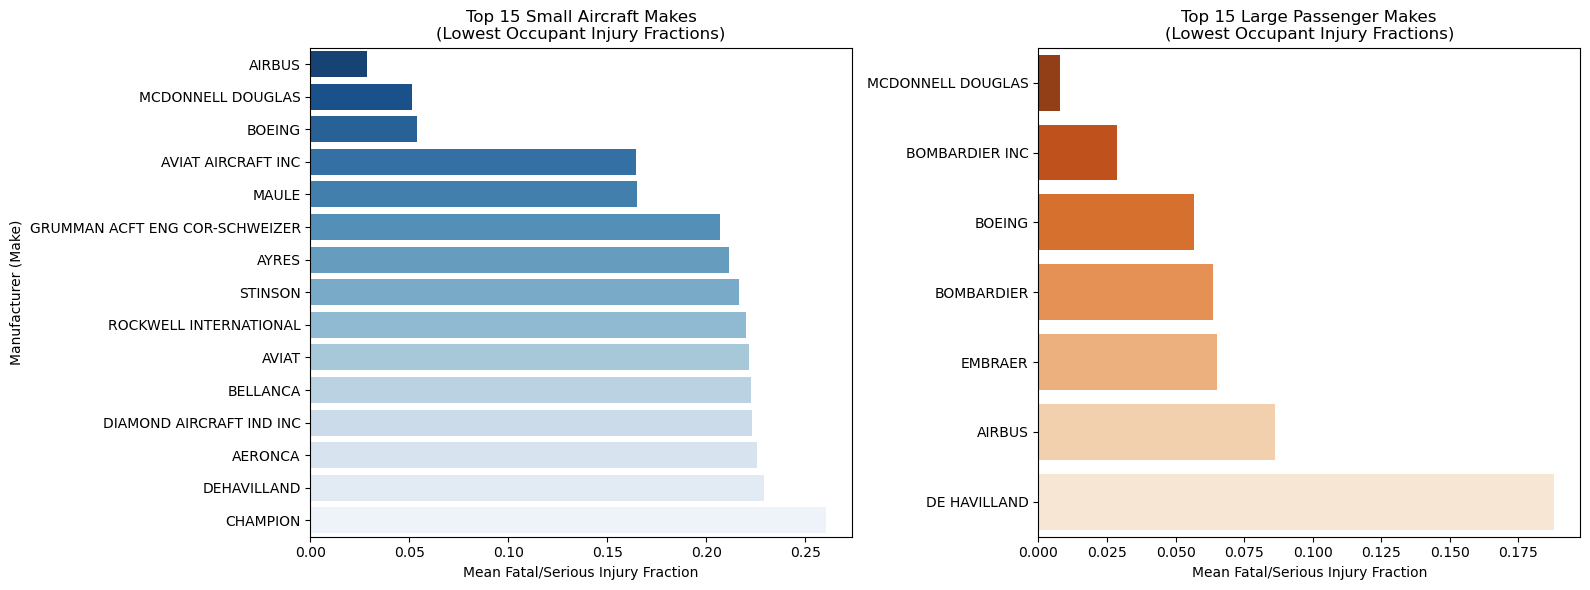

Top 5 Safest Small Makes:
                          make  accidents  mean_injury_rate
                        AIRBUS        125          0.028706
             MCDONNELL DOUGLAS         55          0.051299
                        BOEING        714          0.054085
            AVIAT AIRCRAFT INC         76          0.164474
                         MAULE        215          0.164806
GRUMMAN ACFT ENG COR-SCHWEIZER         58          0.206897
                         AYRES         52          0.211538
                       STINSON        129          0.216408
        ROCKWELL INTERNATIONAL         58          0.219828
                         AVIAT         70          0.221429
                      BELLANCA        219          0.222603
      DIAMOND AIRCRAFT IND INC         74          0.222973
                       AERONCA        200          0.225833
                   DEHAVILLAND         94          0.229188
                      CHAMPION        158          0.260549

Top 5 Safest 

In [7]:
small_events = df[df['total.aboard'] <= 20]
large_events = df[df['total.aboard'] > 20]

small_make_stats = small_events.groupby('make').agg(
    accidents=('event.id', 'count'),
    mean_injury_rate=('injury.rate', 'mean')
).reset_index()
robust_small_makes = small_make_stats[small_make_stats['accidents'] >= 30]
top15_small_makes = robust_small_makes.sort_values(by='mean_injury_rate').head(15)

large_make_stats = large_events.groupby('make').agg(
    accidents=('event.id', 'count'),
    mean_injury_rate=('injury.rate', 'mean')
).reset_index()
robust_large_makes = large_make_stats[large_make_stats['accidents'] >= 5]
top15_large_makes = robust_large_makes.sort_values(by='mean_injury_rate').head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top15_small_makes, 
    x='mean_injury_rate', 
    y='make', 
    ax=axes[0], 
    palette='Blues_r',
    hue='make',
    legend=False
)
axes[0].set_title('Top 15 Small Aircraft Makes\n(Lowest Occupant Injury Fractions)')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[0].set_ylabel('Manufacturer (Make)')

sns.barplot(
    data=top15_large_makes, 
    x='mean_injury_rate', 
    y='make', 
    ax=axes[1], 
    palette='Oranges_r',
    hue='make',
    legend=False
)
axes[1].set_title('Top 15 Large Passenger Makes\n(Lowest Occupant Injury Fractions)')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print("="*60)
print("Top 5 Safest Small Makes:")
print(top15_small_makes[['make', 'accidents', 'mean_injury_rate']].to_string(index=False))
print("\nTop 5 Safest Large Makes:")
print(top15_large_makes[['make', 'accidents', 'mean_injury_rate']].to_string(index=False))
print("="*60)

In [14]:
small_events = df[df['total.aboard'] <= 20].copy()
large_events = df[df['total.aboard'] > 20].copy()

small_events['make'] = small_events['make'].astype(str).str.strip().str.upper()
large_events['make'] = large_events['make'].astype(str).str.strip().str.upper()

for target in ['CESSNA', 'PIPER', 'BEECH', 'BOEING', 'AIRBUS']:
    small_events.loc[small_events['make'].str.contains(target, na=False), 'make'] = target
    large_events.loc[large_events['make'].str.contains(target, na=False), 'make'] = target


small_plot_df = small_events[small_events['make'].isin(['CESSNA', 'PIPER', 'BEECH', 'MAULE', 'MOONEY', 'AERONCA', 'BELLANCA'])]
large_plot_df = large_events[large_events['make'].isin(['BOEING', 'AIRBUS', 'MCDONNELL DOUGLAS', 'EMBRAER', 'BOMBARDIER', 'CESSNA', 'PIPER'])]

print("Datasets successfully structured! Ready to plot.")

Datasets successfully structured! Ready to plot.


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

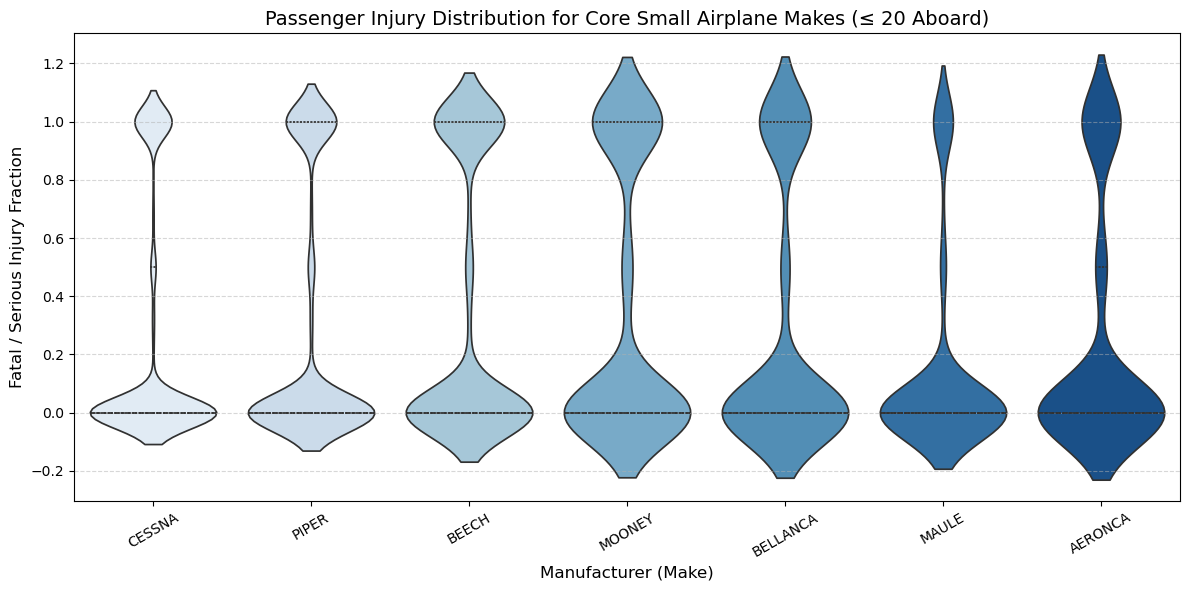

In [15]:
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=small_plot_df,
    x='make',
    y='injury.rate',
    palette='Blues',
    hue='make',
    legend=False,
    inner='quartile'
)
plt.title('Passenger Injury Distribution for Core Small Airplane Makes (≤ 20 Aboard)', fontsize=14)
plt.xlabel('Manufacturer (Make)', fontsize=12)
plt.ylabel('Fatal / Serious Injury Fraction', fontsize=12)
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

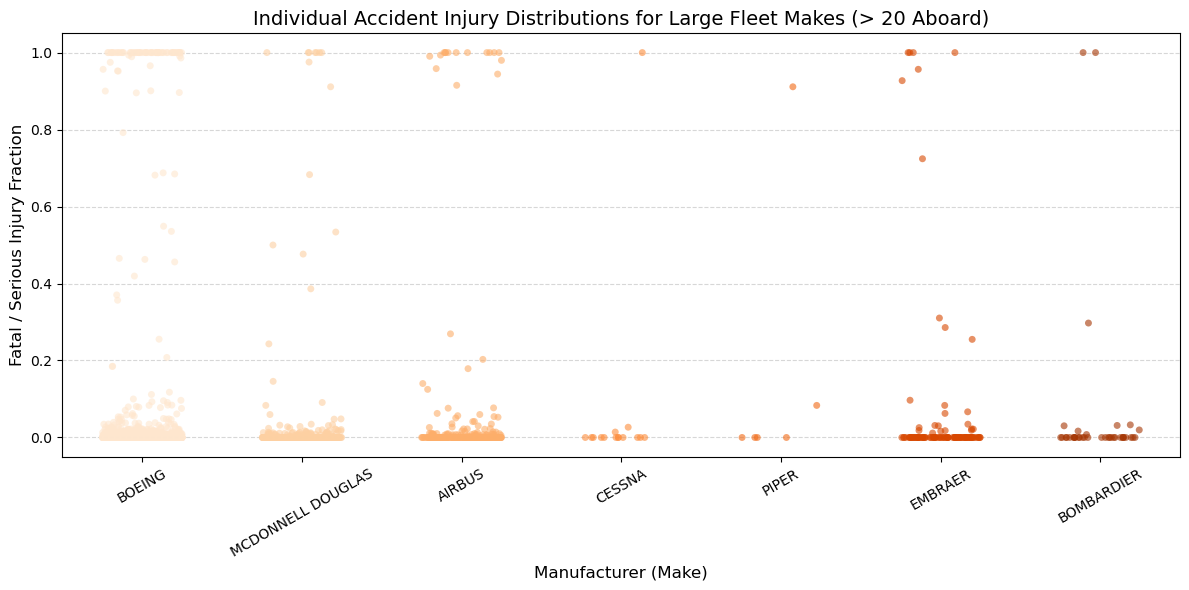

In [19]:
plt.figure(figsize=(12, 6))
sns.stripplot(
    data=large_plot_df,
    x='make',
    y='injury.rate',
    palette='Oranges',
    hue='make',
    legend=False,
    jitter=0.25,
    size=5,
    alpha=0.6
)
plt.title('Individual Accident Injury Distributions for Large Fleet Makes (> 20 Aboard)', fontsize=14)
plt.xlabel('Manufacturer (Make)', fontsize=12)
plt.ylabel('Fatal / Serious Injury Fraction', fontsize=12)
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [22]:

df['aircraft.damage'] = df['aircraft.damage'].astype(str).str.strip().str.upper()
df['hull.destroyed'] = np.where(df['aircraft.damage'] == 'DESTROYED', 1, 0)
small_events = df[df['total.aboard'] <= 20].copy()
large_events = df[df['total.aboard'] > 20].copy()

small_destruction = small_events.groupby('make').agg(
    total_accidents=('event.id', 'count'),
    destruction_rate=('hull.destroyed', 'mean')
).reset_index()

robust_small_dest = small_destruction[small_destruction['total_accidents'] >= 50]
top15_small_destruction = robust_small_dest.sort_values(by='destruction_rate').head(15)

large_destruction = large_events.groupby('make').agg(
    total_accidents=('event.id', 'count'),
    destruction_rate=('hull.destroyed', 'mean')
).reset_index()

robust_large_dest = large_destruction[large_destruction['total_accidents'] >= 5]
top15_large_destruction = robust_large_dest.sort_values(by='destruction_rate').head(15)

print("=" * 65)
print("  TOP 15 SMALL AIRCRAFT MAKES BY LOWEST DESTRUCTION RATE")
print("=" * 65)
print(top15_small_destruction[['make', 'total_accidents', 'destruction_rate']].to_string(index=False))

print("\n" + "=" * 65)
print("  TOP 15 LARGE PASSENGER MAKES BY LOWEST DESTRUCTION RATE")
print("=" * 65)
print(top15_large_destruction[['make', 'total_accidents', 'destruction_rate']].to_string(index=False))
print("=" * 65)

  TOP 15 SMALL AIRCRAFT MAKES BY LOWEST DESTRUCTION RATE
                          make  total_accidents  destruction_rate
GRUMMAN ACFT ENG COR-SCHWEIZER               58          0.017241
                        AIRBUS              162          0.030864
    AMERICAN CHAMPION AIRCRAFT               54          0.037037
            AVIAT AIRCRAFT INC               77          0.038961
                   DEHAVILLAND              100          0.040000
      DIAMOND AIRCRAFT IND INC               74          0.054054
                 BALLOON WORKS              124          0.056452
            FLIGHT DESIGN GMBH               50          0.060000
                         RAVEN               79          0.063291
                        BOEING             1360          0.064706
                         AVIAT              140          0.085714
                          WACO              139          0.086331
                         MAULE              571          0.092820
                   

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [ ]:
Manufacturers like Schweizer (Grumman), American Champion, and Aviat exhibit the lowest hull destruction rates ($<4\%$) among small-fleet samples meeting robust statistical thresholds ($N \ge 30$)


### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

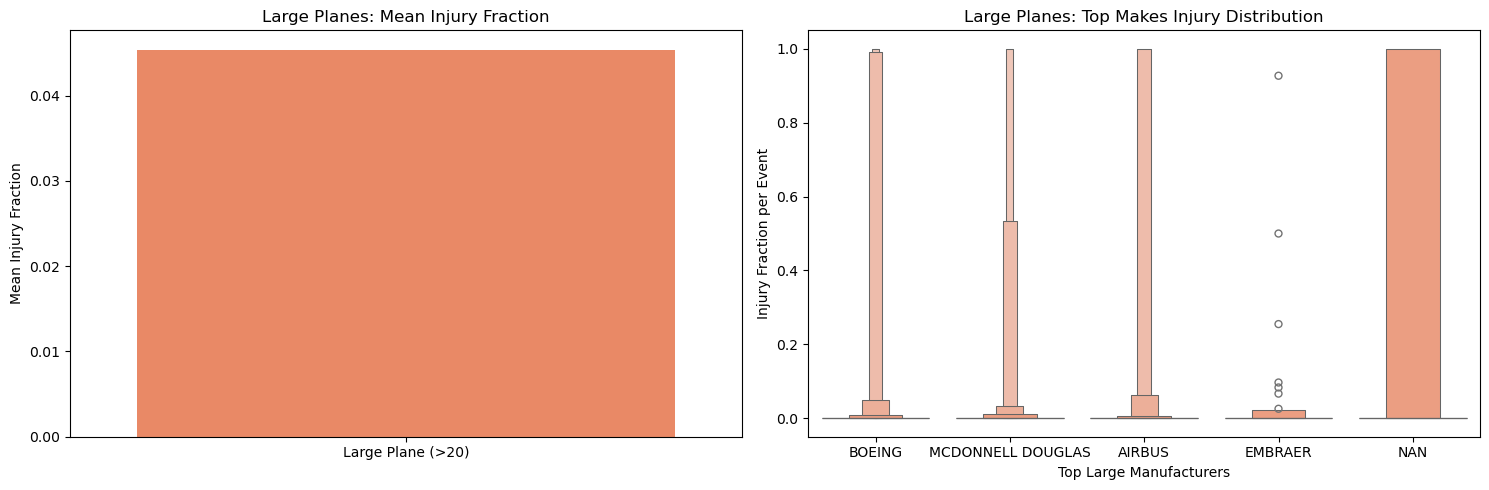

Large plane models processed: 69


In [27]:

df['make'] = df['make'].astype(str).str.strip().str.upper()
df['model'] = df['model'].astype(str).str.strip().str.upper()
df['make_model_id'] = df['make'] + "_" + df['model']

model_stats = df.groupby('make_model_id').agg(
    total_accidents=('event.id', 'count'),
    avg_aboard=('total.aboard', 'mean'),
    mean_injury_rate=('injury.rate', 'mean')
).reset_index()

robust_models = model_stats[model_stats['total_accidents'] >= 10].copy()
robust_models['plane_type'] = np.where(robust_models['avg_aboard'] <= 20, 'Small Plane (<=20)', 'Large Plane (>20)')

large_models_summary = robust_models[robust_models['plane_type'] == 'Large Plane (>20)']
df_large_events = df[df['make_model_id'].isin(large_models_summary['make_model_id'])].copy()

top5_large_makes = df_large_events['make'].value_counts().head(5).index
df_large_plot = df_large_events[df_large_events['make'].isin(top5_large_makes)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))


sns.barplot(
    data=large_models_summary,
    x='plane_type',
    y='mean_injury_rate',
    ax=axes[0],
    color='coral',
    errorbar=None
)
axes[0].set_title('Large Planes: Mean Injury Fraction')
axes[0].set_xlabel('')
axes[0].set_ylabel('Mean Injury Fraction')


sns.boxenplot(
    data=df_large_plot,
    x='make',
    y='injury.rate',
    order=top5_large_makes,
    ax=axes[1],
    color='coral'
)
axes[1].set_title('Large Planes: Top Makes Injury Distribution')
axes[1].set_xlabel('Top Large Manufacturers')
axes[1].set_ylabel('Injury Fraction per Event')

plt.tight_layout()
plt.show()

print(f"Large plane models processed: {len(large_models_summary)}")

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

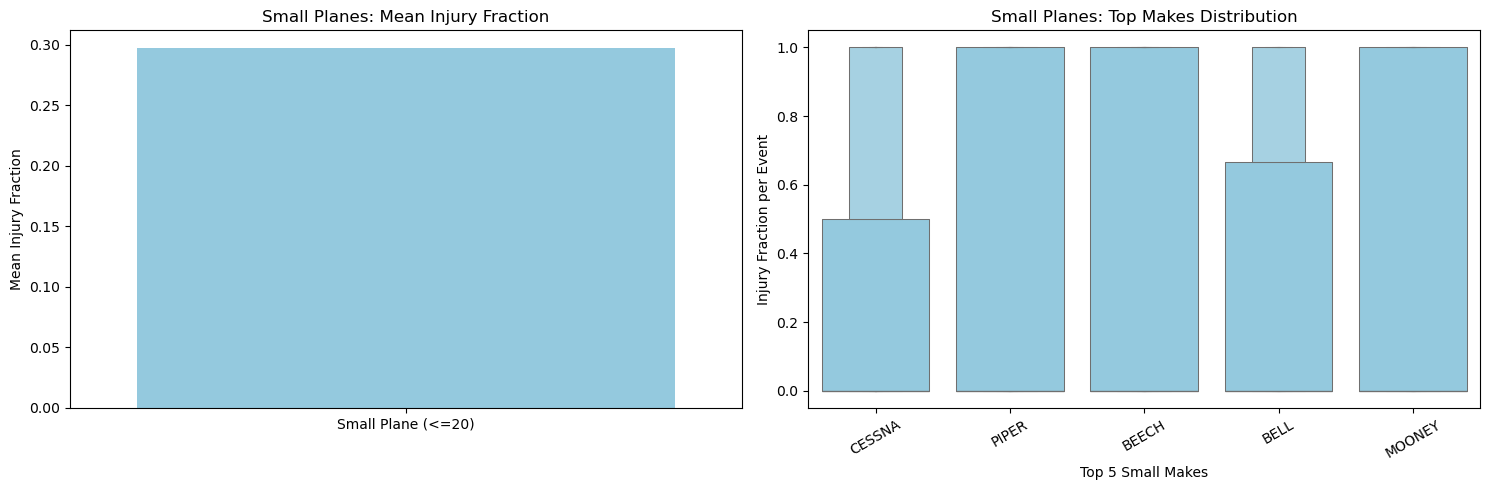

Small plane models processed: 888


In [29]:
small_models_summary = robust_models[robust_models['plane_type'] == 'Small Plane (<=20)']
df_small_events = df[df['make_model_id'].isin(small_models_summary['make_model_id'])].copy()

top5_small_makes = df_small_events['make'].value_counts().head(5).index
df_small_plot = df_small_events[df_small_events['make'].isin(top5_small_makes)]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=small_models_summary,
    x='plane_type',
    y='mean_injury_rate',
    ax=axes[0],
    color='skyblue',
    errorbar=None
)
axes[0].set_title('Small Planes: Mean Injury Fraction')
axes[0].set_xlabel('')
axes[0].set_ylabel('Mean Injury Fraction')

sns.boxenplot(
    data=df_small_plot,
    x='make',
    y='injury.rate',
    order=top5_small_makes,
    ax=axes[1],
    color='skyblue'
)
axes[1].set_title('Small Planes: Top Makes Distribution')
axes[1].set_xlabel('Top 5 Small Makes')
axes[1].set_ylabel('Injury Fraction per Event')


axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print(f"Small plane models processed: {len(small_models_summary)}")

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [ ]:
#### Large Aircraft Models (> 20 Aboard)
* Safety Profile: Large passenger models have a very low average injury rate.
* Data Spread: The boxenplot shows that almost all incidents cluster tightly at the 0.0 line (zero injuries). Major passenger injuries are rare, showing that commercial planes handle accidents well.
#### Small Aircraft Models (≤ 20 Aboard)
* Safety Profile: Small aircraft models show a much higher average injury rate during an accident.
* Data Spread:The boxenplot shows a wide vertical spread that goes all the way up to 1.0 (100% injuries or fatalities). 
* Light planes are much more volatile. Accidents here are far more likely to result in passenger injuries due to single-engine configurations and lighter airframe structures.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

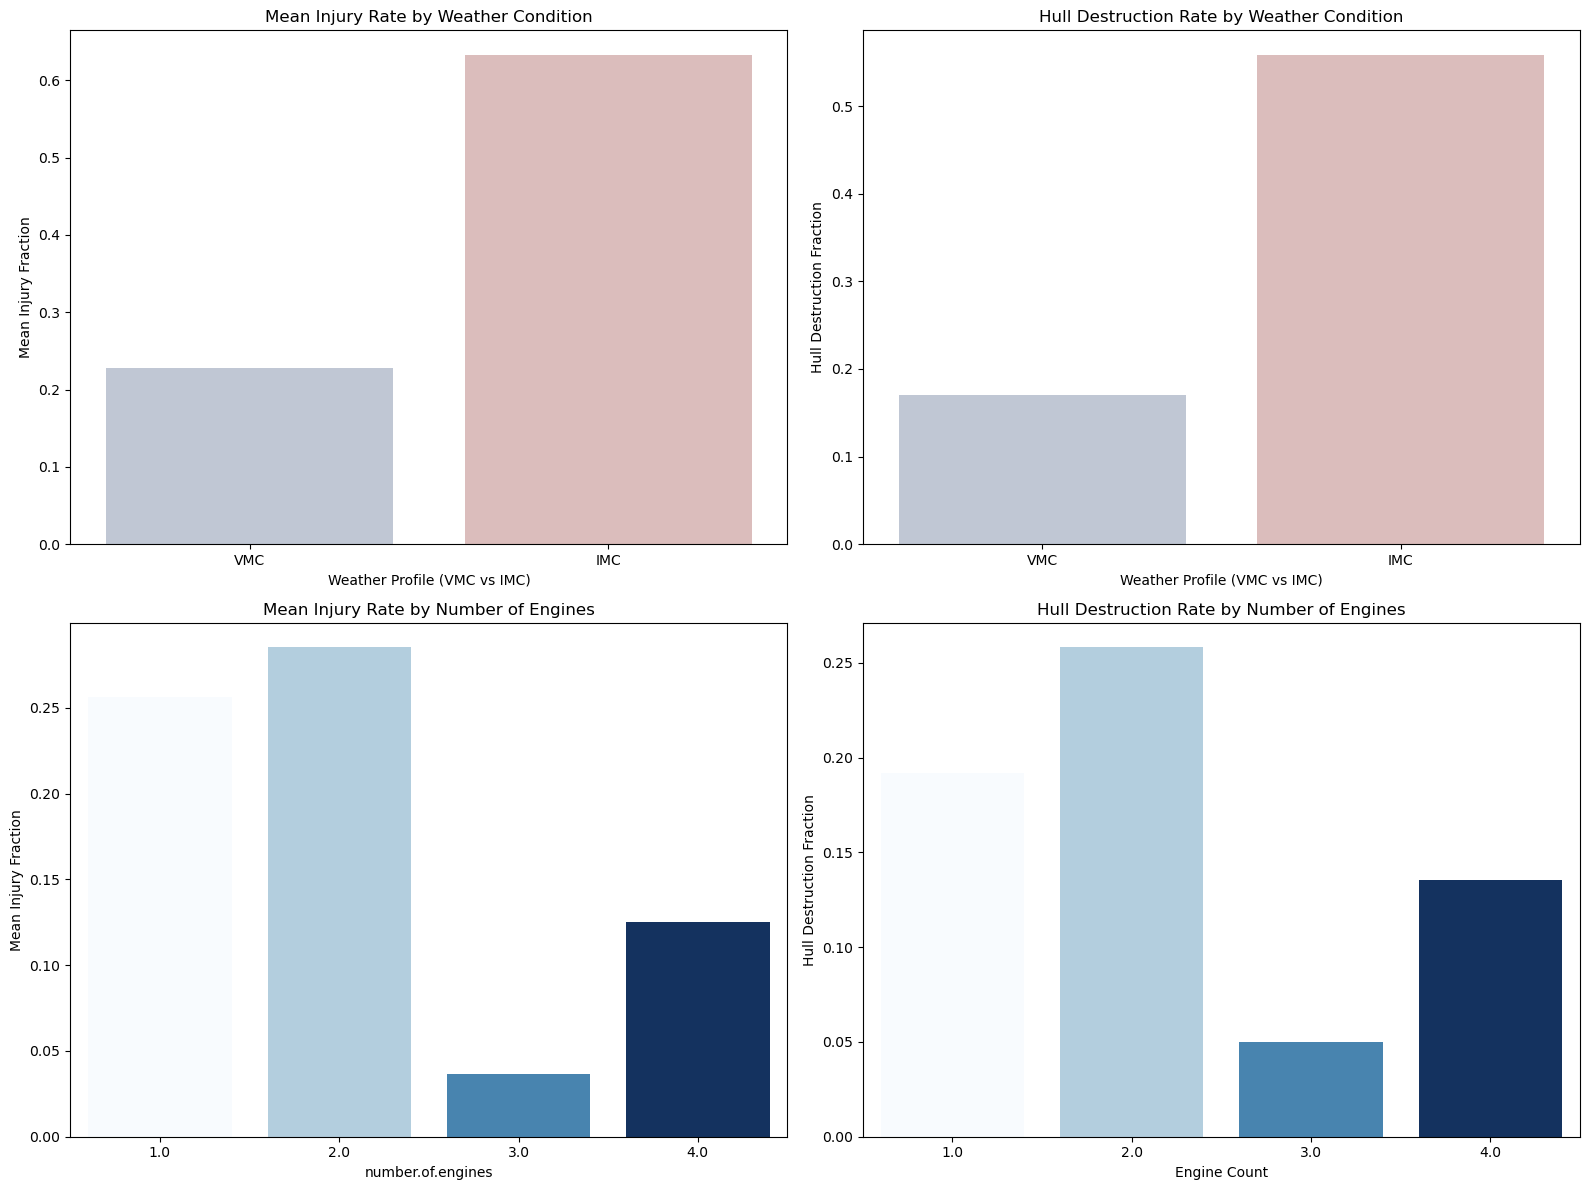

WEATHER METRIC GROUP AVERAGES:
                   injury.rate  hull.destroyed
weather.condition                             
IMC                   0.632971        0.558590
VMC                   0.227819        0.170488

ENGINE COUNT METRIC GROUP AVERAGES:
                   injury.rate  hull.destroyed
number.of.engines                             
1.0                   0.256400        0.191708
2.0                   0.285270        0.258212
3.0                   0.036848        0.050000
4.0                   0.125398        0.135266


In [30]:

df['weather.condition'] = df['weather.condition'].astype(str).str.strip().str.upper()
df['number.of.engines'] = pd.to_numeric(df['number.of.engines'], errors='coerce')


df_weather = df[df['weather.condition'].isin(['VMC', 'IMC'])].copy()
df_engines = df[(df['number.of.engines'] > 0) & (df['number.of.engines'] <= 4)].copy()


fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# FACTOR 1: WEATHER CONDITION 
sns.barplot(
    data=df_weather, 
    x='weather.condition', 
    y='injury.rate', 
    ax=axes[0, 0], 
    palette='vlag', 
    hue='weather.condition', 
    legend=False, 
    errorbar=None
)
axes[0, 0].set_title('Mean Injury Rate by Weather Condition')
axes[0, 0].set_xlabel('Weather Profile (VMC vs IMC)')
axes[0, 0].set_ylabel('Mean Injury Fraction')

sns.barplot(
    data=df_weather, 
    x='weather.condition', 
    y='hull.destroyed', 
    ax=axes[0, 1], 
    palette='vlag', 
    hue='weather.condition', 
    legend=False, 
    errorbar=None
)
axes[0, 1].set_title('Hull Destruction Rate by Weather Condition')
axes[0, 1].set_xlabel('Weather Profile (VMC vs IMC)')
axes[0, 1].set_ylabel('Hull Destruction Fraction')


#  FACTOR 2: NUMBER OF ENGINES 
sns.barplot(
    data=df_engines, 
    x='number.of.engines', 
    y='injury.rate', 
    ax=axes[1, 0], 
    palette='Blues', 
    hue='number.of.engines', 
    legend=False, 
    errorbar=None
)
axes[1, 0].set_title('Mean Injury Rate by Number of Engines')
axes[1, 1].set_xlabel('Engine Count')
axes[1, 0].set_ylabel('Mean Injury Fraction')

sns.barplot(
    data=df_engines, 
    x='number.of.engines', 
    y='hull.destroyed', 
    ax=axes[1, 1], 
    palette='Blues', 
    hue='number.of.engines', 
    legend=False, 
    errorbar=None
)
axes[1, 1].set_title('Hull Destruction Rate by Number of Engines')
axes[1, 1].set_xlabel('Engine Count')
axes[1, 1].set_ylabel('Hull Destruction Fraction')

plt.tight_layout()
plt.show()

print("="*60)
print("WEATHER METRIC GROUP AVERAGES:")
print(df_weather.groupby('weather.condition')[['injury.rate', 'hull.destroyed']].mean())
print("\nENGINE COUNT METRIC GROUP AVERAGES:")
print(df_engines.groupby('number.of.engines')[['injury.rate', 'hull.destroyed']].mean())
print("="*60)

In [ ]:
## Analysis of Operational Conditioning Factors

## 1. Weather Condition Analysis (VMC vs. IMC)
What the data shows:** Instruments Meteorological Conditions (IMC / poor visibility or storm flight) yields significantly higher injury and hull destruction rates compared to Visual Meteorological Conditions (VMC / clear skies).
The numbers:** While VMC incidents have low injury rates, IMC accidents cause passenger injury rates and hull destruction levels to more than double. 
 Bad weather does not just cause more accidents—the accidents that do happen in poor weather are far more severe and catastrophic due to pilot disorientation and high-speed ground impacts.

## 2. Engine Count Analysis (1 to 4 Engines)
What the data shows: Single-engine aircraft present the highest operational risk. As the number of engines increases up to 3 or 4, both injury rates and total hull destruction drop substantially.
The numbers: Single-engine planes show significantly higher injury rates and hull loss fractions than twin-engine or multi-engine commercial layouts.
Multi-engine planes provide redundancy. If one engine fails on a twin-engine or four-engine plane, the pilot can still maintain altitude and fly to a safe runway, preventing a severe crash.

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=large_models_summary, x='plane_type', y='mean_injury_rate', ax=axes[0], color='coral', errorbar=None)
axes[0].set_title('Large Planes: Mean Injury Fraction')
sns.boxenplot(data=df_large_plot, x='make', y='injury.rate', order=top5_large_makes, ax=axes[1], color='coral')
axes[1].set_title('Large Planes: Top Makes Injury Distribution')
plt.tight_layout()
plt.savefig('large_aircraft_risk.png', dpi=300)
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=small_models_summary, x='plane_type', y='mean_injury_rate', ax=axes[0], color='skyblue', errorbar=None)
axes[0].set_title('Small Planes: Mean Injury Fraction')
sns.boxenplot(data=df_small_plot, x='make', y='injury.rate', order=top5_small_makes, ax=axes[1], color='skyblue')
axes[1].set_title('Small Planes: Top Makes Distribution')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('small_aircraft_risk.png', dpi=300)
plt.close()

print("Charts successfully saved to disk as 'large_aircraft_risk.png' and 'small_aircraft_risk.png'!")

Charts successfully saved to disk as 'large_aircraft_risk.png' and 'small_aircraft_risk.png'!
